In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

from sklearn.model_selection import (
    StratifiedKFold,
    GridSearchCV,
    cross_validate,
    cross_val_predict
)
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    make_scorer,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
    roc_curve,
    roc_auc_score
)

RANDOM_STATE = 42

In [2]:
DATA_PATH = Path("../Data/clean_data.csv")

df = pd.read_csv(DATA_PATH)

print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nTarget distribution:")
print(df["279"].value_counts())

df.head()

Dataset shape: (430, 262)

Column names:
['0', '1', '2', '3', '4', '5', '6', '7', '8', '9', '10', '11', '12', '14', '15', '16', '17', '18', '20', '21', '22', '23', '24', '25', '26', '27', '28', '29', '30', '31', '32', '33', '34', '35', '36', '37', '38', '39', '40', '41', '42', '43', '44', '45', '46', '47', '48', '49', '50', '51', '52', '53', '54', '55', '56', '57', '58', '59', '60', '61', '62', '63', '64', '65', '66', '68', '70', '71', '72', '73', '74', '75', '76', '77', '78', '79', '80', '81', '82', '84', '85', '86', '87', '88', '89', '90', '91', '92', '93', '94', '95', '96', '97', '98', '99', '100', '101', '102', '103', '104', '105', '106', '107', '108', '109', '110', '111', '112', '113', '114', '115', '116', '117', '118', '119', '120', '121', '122', '123', '124', '125', '126', '127', '128', '129', '130', '133', '134', '135', '136', '137', '138', '140', '142', '144', '146', '147', '148', '149', '150', '152', '153', '154', '155', '158', '159', '160', '161', '162', '163', '165', '166',

,0,1,2,3,4,5,6,7,8,9,...,269,270,271,272,273,275,276,277,278,279
0,75,0,190.0,80.0,91,193,371,174,121,-16,...,-0.3,0.0,9.0,-0.9,0.0,0.9,2.9,23.3,49.4,1
1,56,1,165.0,64.0,81,174,401,149,39,25,...,-0.5,0.0,8.5,0.0,0.0,0.2,2.1,20.4,38.8,1
2,54,0,172.0,95.0,138,163,386,185,102,96,...,0.9,0.0,9.5,-2.4,0.0,0.3,3.4,12.3,49.0,1
3,55,0,175.0,94.0,100,202,380,179,143,28,...,0.1,0.0,12.2,-2.2,0.0,0.4,2.6,34.6,61.6,0
4,75,0,190.0,80.0,88,181,360,177,103,-16,...,-0.4,0.0,13.1,-3.6,0.0,-0.1,3.9,25.4,62.8,1


In [3]:
TARGET_COLUMN = "279"

X = df.drop(columns=[TARGET_COLUMN])
y = df[TARGET_COLUMN].astype(int)

print("Features shape:", X.shape)
print("Target shape:", y.shape)
print("\nClass distribution:")
print(y.value_counts())

Features shape: (430, 261)
Target shape: (430,)

Class distribution:
279
0    245
1    185
Name: count, dtype: int64


In [4]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

f1_scorer = make_scorer(
    f1_score,
    pos_label=1,
    zero_division=0
)

print("Cross-validation setup complete.")

Cross-validation setup complete.


In [5]:
# Random Forest pipeline
rf_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("classifier", RandomForestClassifier(random_state=RANDOM_STATE))
])

rf_params = {
    "classifier__n_estimators": [100, 200, 300],
    "classifier__max_depth": [None, 10, 20],
    "classifier__min_samples_split": [2, 5]
}

rf_search = GridSearchCV(
    rf_pipeline,
    rf_params,
    cv=cv,
    scoring=f1_scorer,
    n_jobs=-1,
    return_train_score=False
)

rf_search.fit(X, y)

print("Best Random Forest parameters:")
print(rf_search.best_params_)
print("Best Random Forest F1:", round(rf_search.best_score_, 4))

Best Random Forest parameters:
{'classifier__max_depth': None, 'classifier__min_samples_split': 2, 'classifier__n_estimators': 100}
Best Random Forest F1: 0.8126


In [6]:
# RBF SVM pipeline
svm_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("classifier", SVC(kernel="rbf"))
])

svm_params = {
    "classifier__C": [0.1, 1, 10, 100],
    "classifier__gamma": ["scale", 0.01, 0.1, 1]
}

svm_search = GridSearchCV(
    svm_pipeline,
    svm_params,
    cv=cv,
    scoring=f1_scorer,
    n_jobs=-1,
    return_train_score=False
)

svm_search.fit(X, y)

print("Best SVM parameters:")
print(svm_search.best_params_)
print("Best SVM F1:", round(svm_search.best_score_, 4))

Best SVM parameters:
{'classifier__C': 1, 'classifier__gamma': 'scale'}
Best SVM F1: 0.7059


In [7]:
tuning_results = pd.DataFrame([
    {
        "Model": "Random Forest",
        "Baseline F1": 0.8126,
        "Tuned F1": rf_search.best_score_,
        "Best Parameters": str(rf_search.best_params_)
    },
    {
        "Model": "RBF SVM",
        "Baseline F1": 0.7059,
        "Tuned F1": svm_search.best_score_,
        "Best Parameters": str(svm_search.best_params_)
    }
])

tuning_results.to_csv("tuning_results.csv", index=False)

tuning_results

,Model,Baseline F1,Tuned F1,Best Parameters
0,Random Forest,0.8126,0.812646,"{'classifier__max_depth': None, 'classifier__m..."
1,RBF SVM,0.7059,0.705942,"{'classifier__C': 1, 'classifier__gamma': 'sca..."


In [8]:
best_model = rf_search.best_estimator_

# Predicted classes for each held-out fold
y_pred = cross_val_predict(
    best_model,
    X,
    y,
    cv=cv,
    method="predict",
    n_jobs=-1
)

# Predicted probabilities for the positive class (Arrhythmia = 1)
y_prob = cross_val_predict(
    best_model,
    X,
    y,
    cv=cv,
    method="predict_proba",
    n_jobs=-1
)[:, 1]

print("Predictions generated successfully!")

Predictions generated successfully!


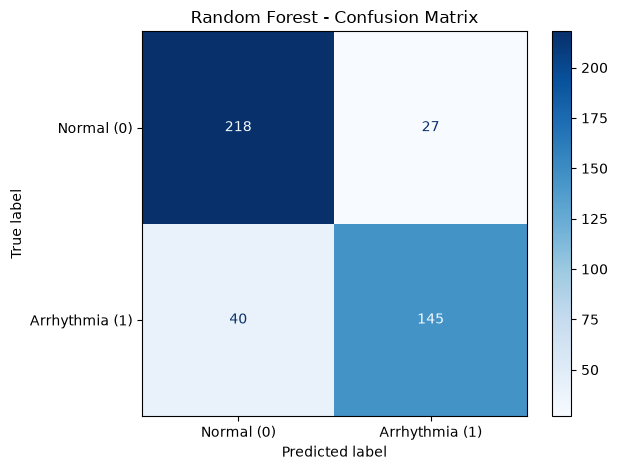

              precision    recall  f1-score   support

      Normal       0.84      0.89      0.87       245
  Arrhythmia       0.84      0.78      0.81       185

    accuracy                           0.84       430
   macro avg       0.84      0.84      0.84       430
weighted avg       0.84      0.84      0.84       430



In [9]:
cm = confusion_matrix(y, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Normal (0)", "Arrhythmia (1)"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Random Forest - Confusion Matrix")
plt.tight_layout()
plt.show()

print(classification_report(
    y,
    y_pred,
    target_names=["Normal", "Arrhythmia"],
    zero_division=0
))

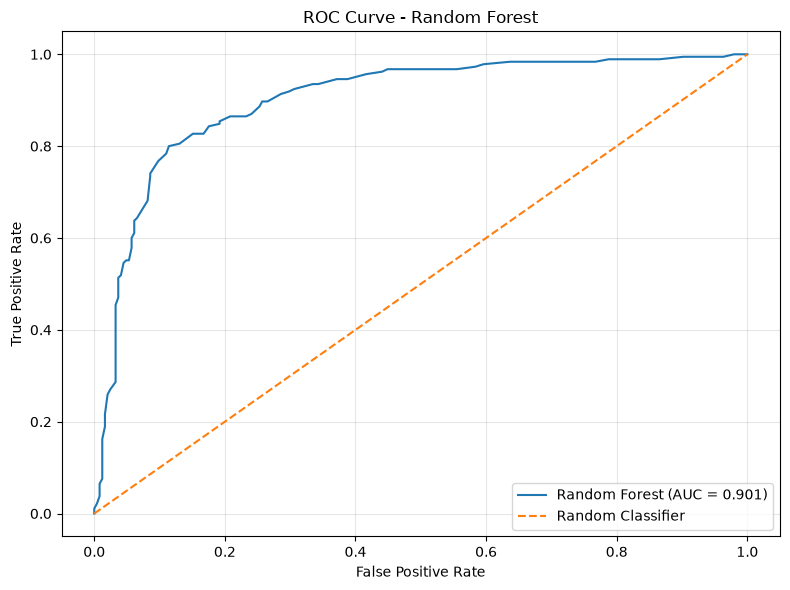

ROC-AUC: 0.9012


In [12]:
fpr, tpr, thresholds = roc_curve(y, y_prob)
roc_auc = roc_auc_score(y, y_prob)

plt.figure(figsize=(8, 6))

plt.plot(
    fpr,
    tpr,
    label=f"Random Forest (AUC = {roc_auc:.3f})"
)

plt.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Random Forest")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(IMAGE_DIR / "random_forest_roc_curve.png",
            dpi=300, bbox_inches="tight")
plt.show()

print("ROC-AUC:", round(roc_auc, 4))

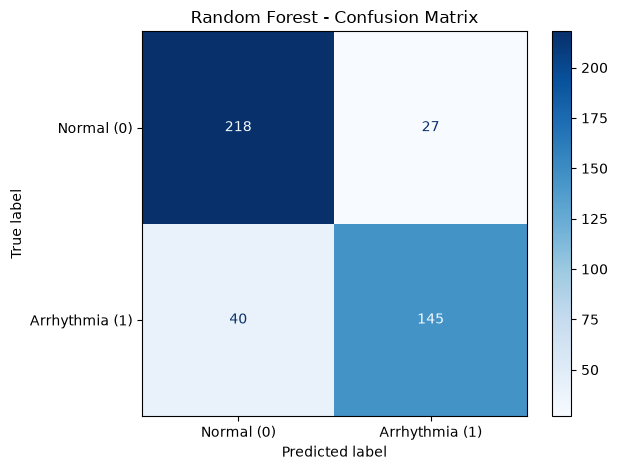

In [13]:
IMAGE_DIR = Path("../Image")
IMAGE_DIR.mkdir(parents=True, exist_ok=True)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Normal (0)", "Arrhythmia (1)"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Random Forest - Confusion Matrix")
plt.tight_layout()
plt.savefig(IMAGE_DIR / "random_forest_confusion_matrix.png",
            dpi=300, bbox_inches="tight")
plt.show()

In [14]:
final_metrics = pd.DataFrame([{
    "Model": "Tuned Random Forest",
    "Accuracy": 0.8442,
    "Precision": 0.8430,
    "Recall": 0.7838,
    "F1 Score": 0.8126,
    "ROC AUC": 0.9012
}])

final_metrics.to_csv("final_model_metrics.csv", index=False)

final_metrics

,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC
0,Tuned Random Forest,0.8442,0.843,0.7838,0.8126,0.9012
